# Site setup — sea level

This notebook configures a National sea-level analysis once and saves the configuration used by the four sea-level indicator notebooks. Sea level has its own setup because it relies on a tide gauge and on satellite altimetry rather than on the GHCN station prepared by the [atmosphere setup](../00_site_setup.ipynb).

It:

1. selects a University of Hawaii Sea Level Center (UHSLC) tide gauge, either by ID, by name or as the station closest to the configured site;
2. resolves the country's exclusive economic zone (EEZ) from `data/regional/Pacific_EEZs/Pacific_EEZs.shp`;
3. downloads the UHSLC Fast Delivery daily and hourly records into `data/sea_level/`;
4. reuses — or downloads — a daily CMEMS L4 altimetry file that covers the EEZ;
5. writes `data/sites/sea_level/<site_key>.json`.

In [1]:
# CIndRA notebook display standard
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 13,
    'figure.dpi': 100,
    'savefig.dpi': 150,
})

In [2]:
from pathlib import Path
import sys

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
import pandas as pd

root_candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
repo_root = next((p for p in root_candidates if (p / 'functions' / 'sea_level.py').is_file()), None)
if repo_root is None:
    raise FileNotFoundError('Could not locate the CIndRA repository root (functions/sea_level.py).')
sys.path.insert(0, str(repo_root / 'functions'))

from sea_level import prepare_site_data, resolve_eez, save_site_config, sea_level_config_path
from sst import normalise_name

## 1. Configuration

Edit this cell to configure another country. `country` must match the `Country` field of the Pacific EEZ shapefile. Leave `selected_uhslc_id` as `None` to use the UHSLC station nearest to (`site_lon`, `site_lat`) among the stations whose country matches `station_country_filter`.

```{note}
Downloading CMEMS altimetry requires a free Copernicus Marine account. Run `copernicusmarine login` once in a terminal; credentials are never stored in the notebooks. When `cmems_file` already covers the EEZ (plus `cmems_padding_degrees`), no download is made.
```

In [3]:
site_config = {
    'site_key': 'Palau',
    'country': 'Palau',                  # EEZ name in Pacific_EEZs.shp
    'site_lon': 134.62,
    'site_lat': 7.34,
    'station_country_filter': 'Palau',   # UHSLC country used to pre-filter stations
    'selected_uhslc_id': None,           # e.g. 7 for Malakal; None selects the nearest station
    'selected_station_name': None,
    'eez_file': 'data/regional/Pacific_EEZs/Pacific_EEZs.shp',
    'sea_level_data_dir': 'data/sea_level',
    'start_date': '1993-01-01',          # first full year of satellite altimetry
    'end_date': '2024-12-31',
    'cmems_file': 'data/sea_level/cmems_L4_SSH_0.125deg_1993_2025.nc',  # reused when it covers the EEZ
    'cmems_padding_degrees': 1.0,
    'cmems_bbox_override': None,         # [west, east, south, north] in 0-360 longitude
    'cmems_start_datetime': '1993-01-01T00:00:00',
    'cmems_end_datetime': '2025-04-30T23:59:59',
    'flood_threshold_cm': 30,            # minor-flood threshold above MHHW
}

## 2. Select the station and prepare the data

In [4]:
site_config, station_options = prepare_site_data(site_config, repo_root)
site_config['site_name'] = '_'.join(normalise_name(site_config['country']).split()) + f"_uhslc{site_config['selected_uhslc_id']:03d}"
print(f"Selected {site_config['station']} (UHSLC {site_config['selected_uhslc_id']:03d}) — "
      f"{site_config['station_distance_km']:.1f} km from the configured site ({site_config['station_selection_reason']}).")
station_options

Selected Malakal (UHSLC 007) — 18.8 km from the configured site (nearest_station).


,uhslc_id,name,country,distance_km,lon,lat,fd_start,fd_end
0,7,Malakal,Palau,18.8,134.450130,7.328520,1969-05-19,2026-09-30
1,438,Imekang,Palau,21.9,134.624995,7.537217,2025-08-26,2026-09-30
2,436,Kamesang,Palau,22.8,134.485257,7.495992,2025-08-27,2026-09-30
3,437,Peleliu,Palau,50.7,134.266473,7.049027,2025-08-29,2026-09-30


## 3. Check the station, EEZ and altimetry domain

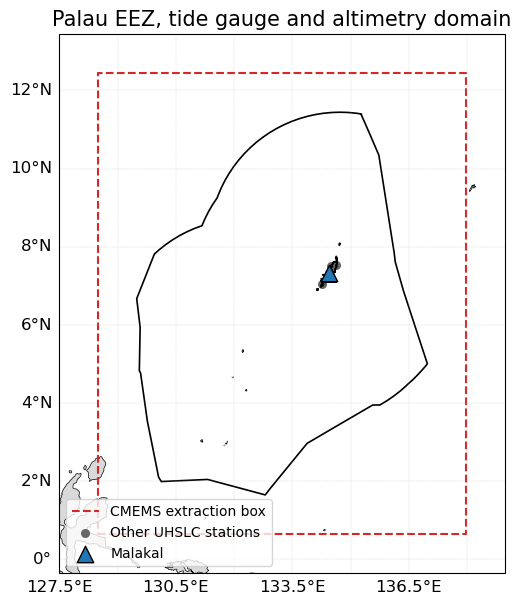

In [5]:
eez, _ = resolve_eez(site_config['country'], repo_root / site_config['eez_file'])
west, east, south, north = site_config['cmems_bounds']
projection = ccrs.PlateCarree(central_longitude=180)
fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={'projection': projection})
ax.set_extent([west - 1, east + 1, south - 1, north + 1], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor='0.85')
ax.coastlines(resolution='10m', linewidth=0.5)
eez.boundary.plot(ax=ax, transform=ccrs.PlateCarree(), color='k', linewidth=1.2)
ax.plot([west, east, east, west, west], [south, south, north, north, south], transform=ccrs.PlateCarree(), color='tab:red', ls='--', label='CMEMS extraction box')
ax.scatter(station_options['lon'], station_options['lat'], transform=ccrs.PlateCarree(), color='0.4', s=30, label='Other UHSLC stations')
ax.scatter(site_config['station_lon'], site_config['station_lat'], transform=ccrs.PlateCarree(), marker='^', s=140, color='tab:blue', edgecolor='k', label=site_config['station'], zorder=5)
gl = ax.gridlines(draw_labels=True, linewidth=0.3, linestyle=':')
gl.top_labels = gl.right_labels = False
ax.legend(loc='lower left', fontsize=10)
ax.set_title(f"{site_config['country']} EEZ, tide gauge and altimetry domain")
plt.show()

## 4. Save the configuration

In [6]:
config_path = sea_level_config_path(repo_root, site_config['site_key'])
save_site_config(site_config, config_path)
print(f'Saved {config_path.relative_to(repo_root)}')
pd.Series(site_config).to_frame('value')

Saved data/sites/sea_level/palau.json


,value
site_key,Palau
country,Palau
site_lon,134.62
site_lat,7.34
station_country_filter,Palau
selected_uhslc_id,7
selected_station_name,None
eez_file,data/regional/Pacific_EEZs/Pacific_EEZs.shp
sea_level_data_dir,data/sea_level
start_date,1993-01-01


## Interpretation and reproducibility notes

- The configuration stores paths relative to the CIndRA root so the notebooks run from any working directory.
- UHSLC Fast Delivery data receive level-1 quality control only and are released within 1–2 months; Research Quality data replace them after 1–2 years.
- The record identifier (`record_id`) in UHSLC NetCDF files encodes station *and* version and differs from the UHSLC station ID; the notebooks always select the single record by position.
- Re-run this notebook after changing the country, the station or the analysis period, then run notebooks a–d in order.